# Simulación de la cafetería UES
Modelo de eventos discretos en SimPy. **Escenario A**: todos pasan por caja y cocina. **Escenario B**: una fracción `p_app` ordena por app y entra directo a cocina.

**Equipo Compuesto por:**
- Noriega Velazquez Jesus Manuel
- Isaac Vivanco Reyna Vanesa
- Hernandez Hernandez Carlos Alberto
- Carmona Catalan Sara de los Sngeles

In [ ]:
!pip install simpy -q

In [ ]:
import simpy, random, statistics as st
import matplotlib.pyplot as plt

# ===== PARÁMETROS (reemplazar con datos medidos) =====
P = dict(
    inter   = 1.5,          # media entre llegadas (min) -> Exponencial
    caja    = (3, 10, 5),   # Triangular (mín, máx, moda) -> min
    cocina  = (10, 30, 15), # Triangular (mín, máx, moda) -> min
    n_caja  = 2,
    n_cocina= 2,
    horizonte = 120,        # min por corrida
)
N_REPLICAS = 30
SEMILLA_BASE = 42           # semillas 42..71

# Chequeo de estabilidad: si rho >= 1 la fila crece sin parar
def rho(P):
    m_caja = sum(P['caja'])/3; m_coc = sum(P['cocina'])/3
    lam = 1/P['inter']
    return lam*m_caja/P['n_caja'], lam*m_coc/P['n_cocina']
print("rho caja, rho cocina (escenario A):", [round(x,2) for x in rho(P)])

rho caja, rho cocina (escenario A): [2.0, 6.11]


## Modelo
`random.triangular(low, high, mode)`. Cada réplica usa su propio generador `random.Random(semilla)` para que sea reproducible. Se mide espera en caja/cocina, tiempo total, **utilización** y **largo de fila**.

In [ ]:
def cliente(env, caja, cocina, usa_app, rng, P, res):
    t0 = env.now
    w_caja = 0.0
    if not usa_app:
        with caja.request() as r:
            yield r
            w_caja = env.now - t0
            yield env.timeout(rng.triangular(P['caja'][0], P['caja'][1], P['caja'][2]))
    t1 = env.now
    with cocina.request() as r:
        yield r
        w_coc = env.now - t1
        yield env.timeout(rng.triangular(P['cocina'][0], P['cocina'][1], P['cocina'][2]))
    res.append(dict(w_caja=w_caja, w_cocina=w_coc, total=env.now - t0, app=usa_app))

def generador(env, caja, cocina, p_app, rng, P, res, cnt):
    while True:
        yield env.timeout(rng.expovariate(1.0 / P['inter']))
        cnt['llegaron'] += 1
        env.process(cliente(env, caja, cocina, rng.random() < p_app, rng, P, res))

def monitor(env, caja, cocina, q, uso, dt=0.1):
    while True:
        uso['caja'] += caja.count*dt; uso['cocina'] += cocina.count*dt
        if abs(env.now - round(env.now)) < 1e-9:      # cada 1 min
            q['caja'].append(len(caja.queue)); q['cocina'].append(len(cocina.queue))
        yield env.timeout(dt)

def replica(seed, p_app, P):
    rng = random.Random(seed)
    env = simpy.Environment()
    caja = simpy.Resource(env, P['n_caja']); cocina = simpy.Resource(env, P['n_cocina'])
    res, cnt = [], {'llegaron': 0}
    q = {'caja': [], 'cocina': []}; uso = {'caja': 0.0, 'cocina': 0.0}
    env.process(generador(env, caja, cocina, p_app, rng, P, res, cnt))
    env.process(monitor(env, caja, cocina, q, uso))
    env.run(until=P['horizonte'])
    m = lambda k: st.mean([r[k] for r in res]) if res else float('nan')
    H = P['horizonte']
    return dict(llegaron=cnt['llegaron'], atendidos=len(res),
        w_caja=m('w_caja'), w_cocina=m('w_cocina'), total=m('total'),
        u_caja=uso['caja']/(P['n_caja']*H), u_cocina=uso['cocina']/(P['n_cocina']*H),
        q_caja=st.mean(q['caja']), q_cocina=st.mean(q['cocina']))

def experimento(p_app, P, n=N_REPLICAS, base=SEMILLA_BASE):
    rs = [replica(base+i, p_app, P) for i in range(n)]
    out = {}
    for k in rs[0]:
        v = [r[k] for r in rs if r[k] == r[k]]
        out[k] = (st.mean(v), 1.96*st.stdev(v)/len(v)**0.5)   # media, IC95 (+/-)
    return out

## Escenario A (situación actual) — 30 réplicas

In [ ]:
A = experimento(0.0, P)
for k, (m, ic) in A.items():
    print(f"{k:10s} {m:7.2f}  ± {ic:.2f}")

llegaron     80.30  ± 2.54
atendidos    11.43  ± 0.37
w_caja        6.52  ± 0.81
w_cocina     28.21  ± 1.07
total        58.66  ± 1.43
u_caja        0.98  ± 0.01
u_cocina      0.93  ± 0.01
q_caja       19.80  ± 1.58
q_cocina     11.42  ± 0.37


## Escenario B — fracción de uso de la app

In [ ]:
fracs = [0.0, 0.10, 0.30, 0.40, 0.50]
tabla = {f: experimento(f, P) for f in fracs}
print(f"{'app':>5} {'esp.caja':>9} {'esp.cocina':>11} {'total':>7} {'u.caja':>7} {'u.coc':>6} {'fila caja':>10} {'fila coc':>9} {'atend/llegaron':>15}")
base_total = tabla[0.0]['total'][0]
for f, o in tabla.items():
    print(f"{f:5.0%} {o['w_caja'][0]:9.2f} {o['w_cocina'][0]:11.2f} {o['total'][0]:7.2f} "
          f"{o['u_caja'][0]:7.2f} {o['u_cocina'][0]:6.2f} {o['q_caja'][0]:10.1f} {o['q_cocina'][0]:9.1f} "
          f"{o['atendidos'][0]:7.0f}/{o['llegaron'][0]:.0f}   reducción: {100*(1-o['total'][0]/base_total):5.1f}%")

  app  esp.caja  esp.cocina   total  u.caja  u.coc  fila caja  fila coc  atend/llegaron
   0%      6.52       28.21   58.66    0.98   0.93       19.8      11.4      11/80   reducción:   0.0%
  10%      3.60       30.50   57.00    0.97   0.94       15.6      15.2      11/79   reducción:   2.8%
  30%      1.46       33.52   56.62    0.95   0.96        8.6      22.7      12/81   reducción:   3.5%
  40%      0.71       33.76   55.18    0.93   0.96        5.8      26.0      12/81   reducción:   5.9%
  50%      0.42       34.27   54.94    0.89   0.97        3.0      28.7      12/82   reducción:   6.3%


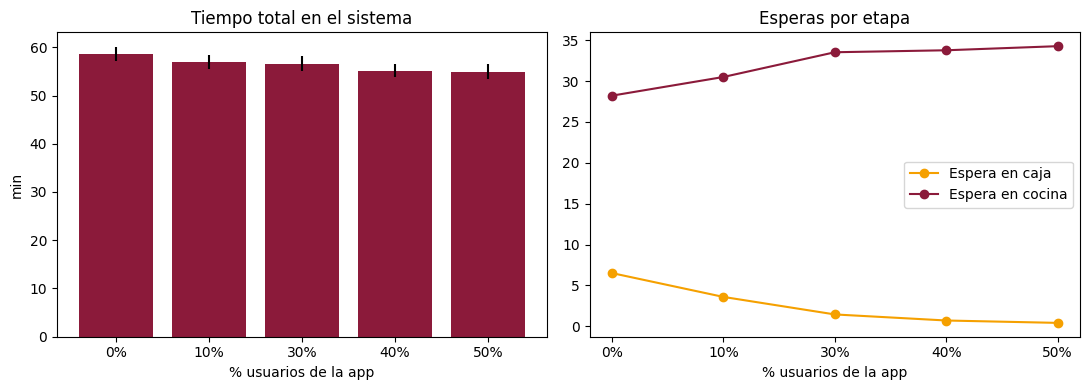

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
x = [f"{int(f*100)}%" for f in fracs]
ax[0].bar(x, [tabla[f]['total'][0] for f in fracs], yerr=[tabla[f]['total'][1] for f in fracs], color="#8B1A3A")
ax[0].set_title("Tiempo total en el sistema"); ax[0].set_xlabel("% usuarios de la app"); ax[0].set_ylabel("min")
ax[1].plot(x, [tabla[f]['w_caja'][0] for f in fracs], marker="o", label="Espera en caja", color="#F5A000")
ax[1].plot(x, [tabla[f]['w_cocina'][0] for f in fracs], marker="o", label="Espera en cocina", color="#8B1A3A")
ax[1].set_title("Esperas por etapa"); ax[1].set_xlabel("% usuarios de la app"); ax[1].legend()
plt.tight_layout(); plt.show()

## Experimento: número de cocineros × uso de la app
Sirve para ver cuál es el **cuello de botella real**.

cocineros=2 app=0% | caja   6.5 | cocina  28.2 | total  58.7 | util.cocina 0.93
cocineros=2 app=30% | caja   1.5 | cocina  33.5 | total  56.6 | util.cocina 0.96
cocineros=2 app=50% | caja   0.4 | cocina  34.3 | total  54.9 | util.cocina 0.97
cocineros=4 app=0% | caja  13.5 | cocina  13.7 | total  51.3 | util.cocina 0.91
cocineros=4 app=30% | caja   3.4 | cocina  24.5 | total  49.2 | util.cocina 0.94
cocineros=4 app=50% | caja   1.3 | cocina  26.8 | total  48.5 | util.cocina 0.95
cocineros=6 app=0% | caja  19.8 | cocina   2.2 | total  45.9 | util.cocina 0.86
cocineros=6 app=30% | caja   5.0 | cocina  15.0 | total  41.4 | util.cocina 0.92
cocineros=6 app=50% | caja   1.4 | cocina  19.9 | total  42.0 | util.cocina 0.93
cocineros=8 app=0% | caja  21.0 | cocina   0.0 | total  45.0 | util.cocina 0.68
cocineros=8 app=30% | caja   6.7 | cocina   7.5 | total  35.9 | util.cocina 0.89
cocineros=8 app=50% | caja   1.4 | cocina  12.6 | total  34.5 | util.cocina 0.91


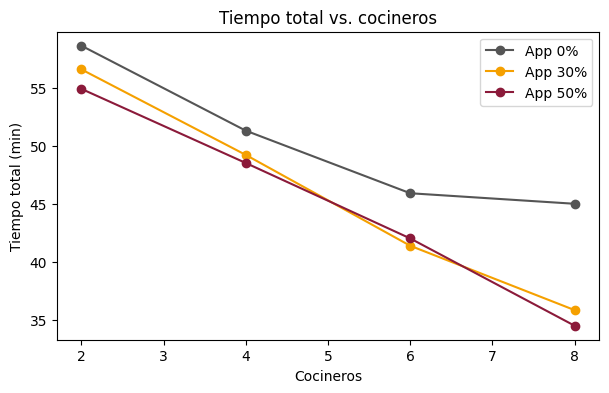

In [ ]:
filas = []
for nc in (2, 4, 6, 8):
    for f in (0.0, 0.30, 0.50):
        o = experimento(f, dict(P, n_cocina=nc))
        filas.append((nc, f, o['w_caja'][0], o['w_cocina'][0], o['total'][0], o['u_cocina'][0]))
        print(f"cocineros={nc} app={f:.0%} | caja {o['w_caja'][0]:5.1f} | cocina {o['w_cocina'][0]:5.1f} | total {o['total'][0]:5.1f} | util.cocina {o['u_cocina'][0]:.2f}")

plt.figure(figsize=(7, 4))
for f, c in zip((0.0, 0.30, 0.50), ("#555", "#F5A000", "#8B1A3A")):
    plt.plot([r[0] for r in filas if r[1] == f], [r[4] for r in filas if r[1] == f], marker="o", label=f"App {f:.0%}", color=c)
plt.xlabel("Cocineros"); plt.ylabel("Tiempo total (min)"); plt.legend(); plt.title("Tiempo total vs. cocineros"); plt.show()

## Histogramas de los datos medidos



---



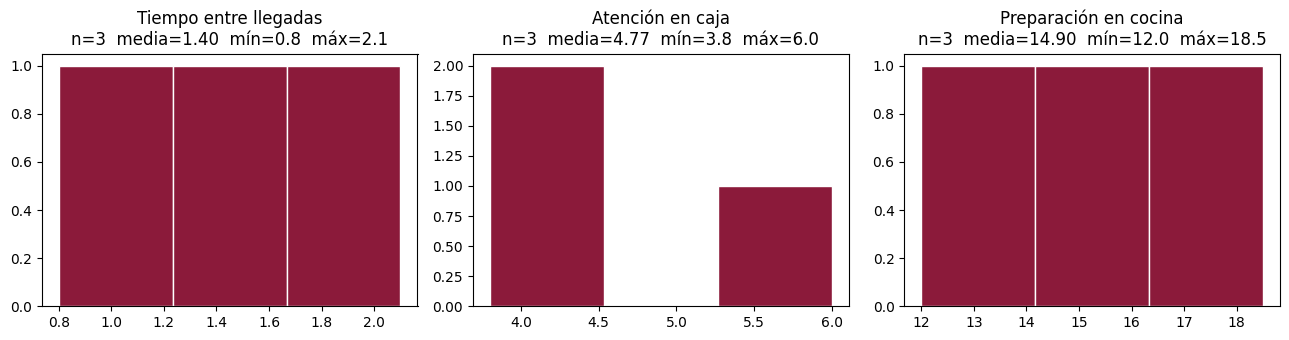

In [ ]:
# Las mediciones reales (minutos)
datos = {
    "Tiempo entre llegadas": [0.8, 2.1, 1.3,],
    "Atención en caja":      [4.5, 6.0, 3.8],
    "Preparación en cocina": [14.2, 18.5, 12.0],
}
fig, axs = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (nombre, v) in zip(axs, datos.items()):
    if len(v) >= 2:
        ax.hist(v, bins="auto", color="#8B1A3A", edgecolor="white")
        ax.set_title(f"{nombre}\nn={len(v)}  media={st.mean(v):.2f}  mín={min(v):.1f}  máx={max(v):.1f}")
    else:
        ax.set_title(f"{nombre}\n(sin datos)")
plt.tight_layout(); plt.show()
